In [1]:
#! ai aided cell to help me fix some import path issues I didnt understand
import sys
from pathlib import Path

root = Path.cwd()
if root.name == "src":
    root = root.parent

if not (root / "src" / "models" / "ViTV1.py").is_file():
    raise RuntimeError(f"Not at the repository root: {root}")

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

In [2]:
import torch
from src.models.ViTV1 import ViT_V1
from src.models.ViTV2 import ViT_V2
from src.train import Checkpoint, load_checkpoint
from src.dataset import TODataset, Mode
from pathlib import Path
from src.utils import visualize, reshape_distribution, preprocess, postprocess, un_one_hot_encode
from src.eval import compliance, rel_compliance_error, rel_volume_error, density_error, evaluate_prediction, evaluate_model

In [3]:
Path.cwd()

WindowsPath('c:/Users/lucas/Desktop/Uni/Lernen/Master/5. Semester/Applied Deep Learning/12435611_topology-optimization/src')

In [4]:
# load data



In [36]:
# load model

path = Path.cwd() / "../trainings/ViT_V2_e96_q48_b3_h3_p8/adam_0.001_bce/epoch_200.pth"
checkpoint: Checkpoint = load_checkpoint(path)
dataset = TODataset(Path("./../data/labeled_data/test"), patch_size=checkpoint.model_spec.patch_size)
model_state_dict = checkpoint.model_state_dict
model = ViT_V2(
    embedding_dims=checkpoint.model_spec.embedding_dims,
    query_dims=checkpoint.model_spec.query_dims,
    n_attention_blocks=checkpoint.model_spec.n_attention_blocks,
    n_attention_heads=checkpoint.model_spec.n_attention_heads,
    patch_size=checkpoint.model_spec.patch_size,
)
model.load_state_dict(checkpoint.model_state_dict)
model.eval()  # set the model to evaluation mode

INFO:root:Loading checkpoint from c:\Users\lucas\Desktop\Uni\Lernen\Master\5. Semester\Applied Deep Learning\12435611_topology-optimization\src\..\trainings\ViT_V2_e96_q48_b3_h3_p8\adam_0.001_bce\epoch_200.pth
INFO:src.dataset:Initializing Dataset with path ..\data\labeled_data\test
INFO:src.dataset:Dataset: n_samples 3000
INFO:src.dataset:Dataset initialized succesfully


ViT_V2(
  (linear_patch): Linear(in_features=64, out_features=96, bias=True)
  (linear_param): Linear(in_features=261, out_features=96, bias=True)
  (readout): Linear(in_features=96, out_features=64, bias=True)
  (linear_vs): ModuleList(
    (0-2): 3 x Linear(in_features=96, out_features=96, bias=True)
  )
  (linear_qs): ModuleList(
    (0-2): 3 x Linear(in_features=96, out_features=48, bias=True)
  )
  (linear_ks): ModuleList(
    (0-2): 3 x Linear(in_features=96, out_features=48, bias=True)
  )
  (linears): ModuleList(
    (0-2): 3 x Linear(in_features=96, out_features=96, bias=True)
  )
  (mlps): ModuleList(
    (0-2): 3 x Sequential(
      (0): Linear(in_features=96, out_features=384, bias=True)
      (1): ReLU()
      (2): Linear(in_features=384, out_features=96, bias=True)
    )
  )
  (attention_norms): ModuleList(
    (0-2): 3 x LayerNorm((96,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (mlp_norms): ModuleList(
    (0-2): 3 x LayerNorm((96,), eps=1e-05, elementwise_af

True density shape: torch.Size([4096])
Predicted density shape: torch.Size([4096])
Stress shape: torch.Size([4096])


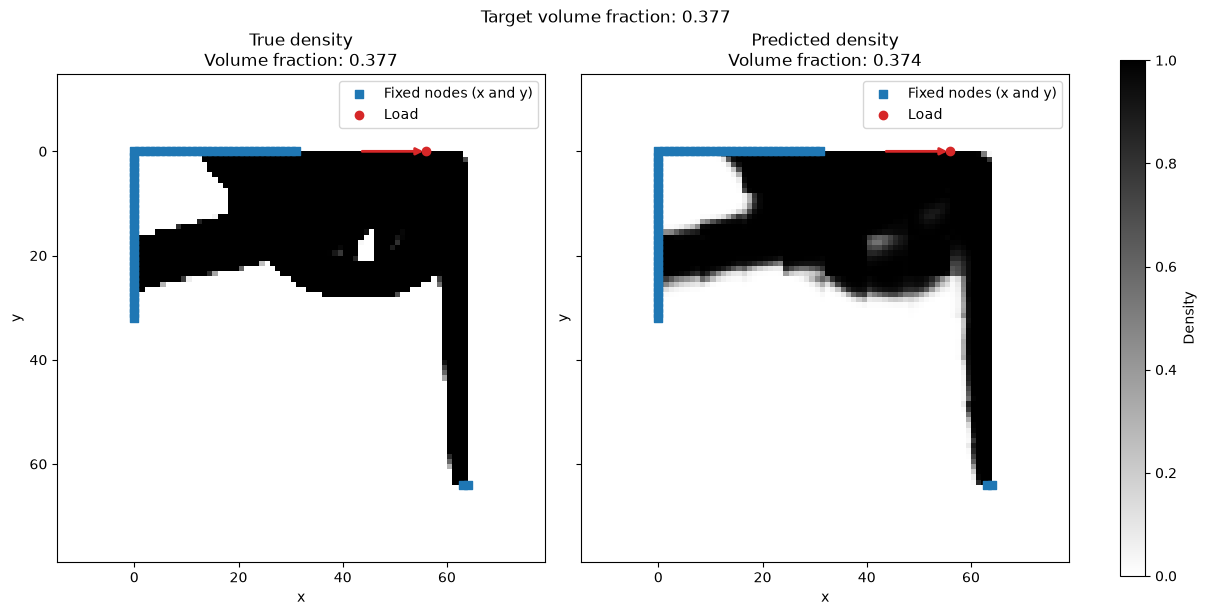

(<Figure size 1200x600 with 3 Axes>,
 array([<Axes: title={'center': 'True density\nVolume fraction: 0.377'}, xlabel='x', ylabel='y'>,
        <Axes: title={'center': 'Predicted density\nVolume fraction: 0.374'}, xlabel='x', ylabel='y'>],
       dtype=object))

In [37]:
from src.utils import orientation_angle


sample_idx = 2 #13 # 10 # 14 #   
# todo: check 103 -> data
sample = dataset[sample_idx]
volume_fraction = sample[0][0]
load = sample[0][1:5]
bcs_one_hot = sample[0][5:5+4*64]
stress = sample[0][5+4*64:]

true_density = sample[1]

# # preprocessing the sample

# angle = orientation_angle(load)

# sample = preprocess(volume_fraction, load, bcs_one_hot, stress, checkpoint.model_spec.patch_size)
with torch.no_grad():
    predicted_density = model(sample[0].unsqueeze(0)).squeeze(0)

# round to 1 or 0
# predicted_density = (predicted_density > 0.5).float()

print("True density shape:", true_density.shape)
print("Predicted density shape:", predicted_density.shape)
print("Stress shape:", stress.shape)

# stress = stress
# true_density = true_density
# with torch.no_grad():
#     predicted_density = predicted_density


visualize(
    true_density,
    predicted_density,
    patch_size=checkpoint.model_spec.patch_size,
    load=load,
    bcs_one_hot=bcs_one_hot,
    volume_fraction=volume_fraction
)



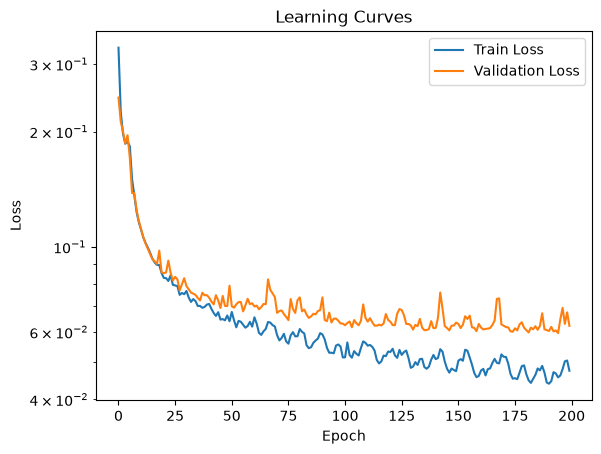

In [38]:
# plot learning curves
from matplotlib import pyplot as plt
results = checkpoint.results
plt.semilogy(results.train_losses, label='Train Loss')
plt.semilogy(results.validation_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Learning Curves')
plt.legend()
plt.show()

In [35]:
binarify_densities = True
# compute compliance
post_processed_true, _, _ = postprocess(true_density, dataset.angles[sample_idx], dataset.patch_size, binarify_densities=binarify_densities) # binaryfiy here too to get SIMP penalized compliance
post_processed_pred_bin, orig_load, orig_bcs = postprocess(predicted_density, dataset.angles[sample_idx], dataset.patch_size, load=load, fixed_dofs_one_hot=bcs_one_hot, binarify_densities=binarify_densities)

# todo: identify compliance units for report
print("Target Compliance:", compliance(post_processed_true, orig_load, orig_bcs))
print("Predicted Compliance:", compliance(post_processed_pred_bin, orig_load, orig_bcs))
print("relative compliance error:", rel_compliance_error(post_processed_pred_bin, post_processed_true, orig_load, orig_bcs, binarify_densities=binarify_densities))

Target Compliance: 5.851129223133037
Predicted Compliance: 5.867267448757136
relative compliance error: 0.0027581386444680608


In [22]:
# evaluate_prediction
from dataclasses import asdict
from pprint import pprint

predicted, orig_load, orig_bcs = postprocess(
    predicted_density, dataset.angles[sample_idx], dataset.patch_size,
    load=load, fixed_dofs_one_hot=bcs_one_hot,
)
target, _, _ = postprocess(true_density, dataset.angles[sample_idx], dataset.patch_size)
evaluation = evaluate_prediction(predicted, target, orig_load, orig_bcs, float(volume_fraction))

pprint(asdict(evaluation), sort_dicts=False, width=1)

{'rel_compliance_error_binary': 0.00022405010372785175,
 'rel_compliance_error_continuous': 0.0006911762563418978,
 'rel_volume_error': 0.00866454467177391,
 'density_error': 1.286213755607605}


In [9]:
model_eval = evaluate_model(
    model,
    dataset
)

INFO:src.eval:Evaluating sample 0/3000
INFO:src.eval:Evaluating sample 1/3000
INFO:src.eval:Evaluating sample 2/3000
INFO:src.eval:Evaluating sample 3/3000
INFO:src.eval:Evaluating sample 4/3000
INFO:src.eval:Evaluating sample 5/3000
INFO:src.eval:Evaluating sample 6/3000
INFO:src.eval:Evaluating sample 7/3000
INFO:src.eval:Evaluating sample 8/3000
INFO:src.eval:Evaluating sample 9/3000
INFO:src.eval:Evaluating sample 10/3000
INFO:src.eval:Evaluating sample 11/3000
INFO:src.eval:Evaluating sample 12/3000
INFO:src.eval:Evaluating sample 13/3000
INFO:src.eval:Evaluating sample 14/3000
INFO:src.eval:Evaluating sample 15/3000
INFO:src.eval:Evaluating sample 16/3000
INFO:src.eval:Evaluating sample 17/3000
INFO:src.eval:Evaluating sample 18/3000
INFO:src.eval:Evaluating sample 19/3000
INFO:src.eval:Evaluating sample 20/3000
INFO:src.eval:Evaluating sample 21/3000
INFO:src.eval:Evaluating sample 22/3000
INFO:src.eval:Evaluating sample 23/3000
INFO:src.eval:Evaluating sample 24/3000
INFO:src.e

KeyboardInterrupt: 

In [ ]:
pprint(asdict(model_eval), sort_dicts=False, width=1)

{'mean_rel_compliance_error_binary': -560505.7840695448,
 'median_rel_compliance_error_binary': -0.007273795034822617,
 'rel_compliance_error_above_30_percent': 0.0,
 'mean_rel_compliance_error_continuous': -229.53457286249824,
 'median_rel_compliance_error_continuous': -0.032789383307008445,
 'rel_compliance_error_continuous_above_30_percent': 0.0,
 'mean_density_error': 0.07159770739482095,
 'median_density_error': 0.06690378487110138,
 'density_error_above_0_1': 0.14933333333333335,
 'mean_rel_volume_error': 0.0030928746667620243,
 'median_rel_volume_error': 0.0042325034737586975,
 'rel_volume_error_above_0_1': 0.13066666666666665,
 'SampleEvaluations': [{'rel_compliance_error_binary': 0.005806639111675026,
                        'rel_compliance_error_continuous': -0.013819534907520817,
                        'rel_volume_error': 0.08975961059331894,
                        'density_error': 0.050160977989435196},
                       {'rel_compliance_error_binary': 0.036652874461